# Cookie Cats: should the first gate stay at level 30?

Cookie Cats is a mobile puzzle game by Tactile Entertainment. While you play you hit "gates" that make you wait (or pay) before continuing. The team ran an A/B test on where the **first** gate should be: at level 30, where it already was, or moved later to level 40.

This notebook works through that experiment end to end: the data audit, retention rates with uncertainty, the actual hypothesis tests, a randomization check, a bootstrap cross-check, a power analysis, and a look at whether the effect depends on how much people play.

**Data:** 90,189 players who installed the game during the test. [Mobile Games A/B Testing - Cookie Cats on Kaggle](https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats).

## 1. The question and the plan

**Question:** does moving the first gate from level 30 to level 40 change how many players come back?

- **Control (`gate_30`)**: gate at level 30, the existing design
- **Treatment (`gate_40`)**: gate pushed to level 40

**Metrics** (both are "did the player come back", recorded per player):

- **Primary: 7-day retention.** Gates are supposed to pace players so they stick around longer, so the one-week number is the one that matters.
- **Secondary: 1-day retention.** Early signal, but day 1 is too short to judge a pacing change on its own.

**Hypotheses** (two-sided, I don't want to assume the direction before looking):

- H0: retention is the same in both groups
- H1: retention differs

**Decision rule, set before looking at results:**

- alpha = 0.05, and since I'm testing two metrics I'll use a Holm correction so the two tests together stay at 5%
- if `gate_40` is significantly **worse** on 7-day retention and nothing offsets that, keep the gate at level 30
- a win has to beat noise, not just point in the right direction

Before any of that: audit the data and check the randomization, because a clean test on bad assignment means nothing.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

DATA_PATH = Path('data/cookie_cats.csv')
DATA_URL = 'https://raw.githubusercontent.com/ryanschaub/Mobile-Games-A-B-Testing-with-Cookie-Cats/master/cookie_cats.csv'

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    DATA_PATH.parent.mkdir(exist_ok=True)
    df = pd.read_csv(DATA_URL)
    df.to_csv(DATA_PATH, index=False)

df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 2. Data audit

Five columns: `userid`, the assigned `version`, rounds played in the first 14 days, and the two retention flags. Checks: types, missing values, duplicate users, group sizes, and whether the round counts look sane.

In [2]:
print('rows:', len(df))
print(df.dtypes)
print('missing values:', df.isna().sum().sum())
print('duplicate userids:', df['userid'].duplicated().sum())
print()
print(df['version'].value_counts())

rows: 90189
userid             int64
version           object
sum_gamerounds     int64
retention_1         bool
retention_7         bool
dtype: object
missing values: 0
duplicate userids: 0

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


In [3]:
df.groupby('version')['sum_gamerounds'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
version,,,,,,,,
gate_30,44700.0,52.5,256.7,0.0,5.0,17.0,50.0,49854.0
gate_40,45489.0,51.3,103.3,0.0,5.0,16.0,52.0,2640.0


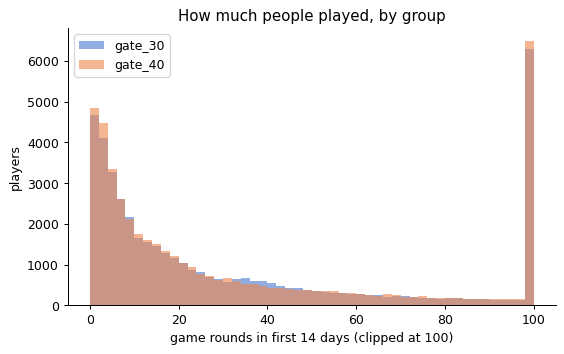

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for version, color in [('gate_30', '#4878d0'), ('gate_40', '#ee854a')]:
    rounds = df.loc[df['version'] == version, 'sum_gamerounds'].clip(upper=100)
    ax.hist(rounds, bins=range(0, 102, 2), alpha=0.6, label=version, color=color)
ax.set_xlabel('game rounds in first 14 days (clipped at 100)')
ax.set_ylabel('players')
ax.set_title('How much people played, by group')
ax.legend()
plt.show()

Clean: no missing values, no duplicate users, roughly 45k per group.

Two things worth noting. The round counts are very skewed: the median player plays 16-17 rounds, but one `gate_30` player logged 49,854 rounds in 14 days, which is either a bot or someone with a serious problem. Since retention is a yes/no flag per player, outliers like that can't drag the main metrics around, so I'm leaving them in. And the split isn't exactly even: 44,700 vs 45,489. I check whether that's within random luck in section 6.

## 3. Retention rates, with uncertainty

A rate from a sample is an estimate, so each one gets a 95% confidence interval. I'm using Wilson intervals because they behave well for proportions, unlike the simple "p plus or minus 2 standard errors" version, which can misbehave near 0 or 1.

In [5]:
def wilson_interval(k, n, z=1.96):
    """95% Wilson score interval for k successes out of n."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

rows = []
for metric in ['retention_1', 'retention_7']:
    for version in ['gate_30', 'gate_40']:
        group = df.loc[df['version'] == version, metric]
        k, n = int(group.sum()), len(group)
        lo, hi = wilson_interval(k, n)
        rows.append({'metric': metric, 'group': version, 'players': n,
                     'retained': k, 'rate': k / n, 'ci_lo': lo, 'ci_hi': hi})

rates = pd.DataFrame(rows)
rates[['rate', 'ci_lo', 'ci_hi']] = rates[['rate', 'ci_lo', 'ci_hi']].round(4)
rates

,metric,group,players,retained,rate,ci_lo,ci_hi
0,retention_1,gate_30,44700,20034,0.4482,0.4436,0.4528
1,retention_1,gate_40,45489,20119,0.4423,0.4377,0.4469
2,retention_7,gate_30,44700,8502,0.1902,0.1866,0.1939
3,retention_7,gate_40,45489,8279,0.1820,0.1785,0.1856


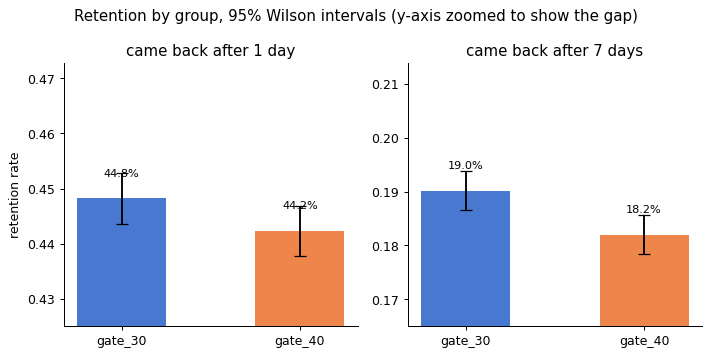

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=False)
for ax, metric, title in zip(axes, ['retention_1', 'retention_7'],
                             ['came back after 1 day', 'came back after 7 days']):
    sub = rates[rates['metric'] == metric]
    x = np.arange(2)
    ax.bar(x, sub['rate'], yerr=[sub['rate'] - sub['ci_lo'], sub['ci_hi'] - sub['rate']],
           capsize=5, color=['#4878d0', '#ee854a'], width=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(sub['group'])
    ax.set_title(title)
    for xi, r in zip(x, sub['rate']):
        ax.text(xi, r + 0.004, f'{r:.1%}', ha='center', fontsize=9)
    lo = (sub['ci_lo'].min() // 0.01) * 0.01
    ax.set_ylim(lo - 0.005, sub['ci_hi'].max() + 0.02)
axes[0].set_ylabel('retention rate')
fig.suptitle('Retention by group, 95% Wilson intervals (y-axis zoomed to show the gap)')
fig.tight_layout()
plt.show()

Both metrics sit lower in `gate_40`. For 1-day retention the intervals overlap, so that gap could still be luck. For 7-day retention they don't overlap at all, which is the first sign the day-7 gap is real. Sections 5 and 7 put that on firm ground. (The y-axes above are zoomed in so the differences are visible, that's why the bars look dramatic.)

## 4. How big is the difference

Statistical significance comes later; first the size. Absolute difference in percentage points, relative change versus control, and a 95% interval for the difference itself.

In [7]:
def difference_summary(metric):
    a = df.loc[df['version'] == 'gate_30', metric]
    b = df.loc[df['version'] == 'gate_40', metric]
    p1, p2 = a.mean(), b.mean()
    diff = p1 - p2  # positive means gate_40 is worse
    se = np.sqrt(p1 * (1 - p1) / len(a) + p2 * (1 - p2) / len(b))
    return {'metric': metric, 'gate_30': p1, 'gate_40': p2,
            'abs_diff_pp': diff * 100, 'rel_change_pct': -diff / p1 * 100,
            'diff_ci_lo_pp': (diff - 1.96 * se) * 100,
            'diff_ci_hi_pp': (diff + 1.96 * se) * 100}

effects = pd.DataFrame([difference_summary('retention_1'),
                        difference_summary('retention_7')]).round(3)
effects

,metric,gate_30,gate_40,abs_diff_pp,rel_change_pct,diff_ci_lo_pp,diff_ci_hi_pp
0,retention_1,0.448,0.442,0.591,-1.318,-0.058,1.239
1,retention_7,0.190,0.182,0.820,-4.312,0.312,1.328


Reading the treatment column as the change: moving the gate to level 40 costs about **0.6 points of day-1 retention** and **0.8 points of day-7 retention** (a 4.3% relative drop on day 7). Small numbers, but at 90k installs a 0.8 point drop is roughly 740 players who don't come back per cohort of this size. The day-7 interval excludes zero; the day-1 interval just about touches it.

## 5. Hypothesis tests

Primary test: a two-proportion z-test with a pooled standard error (the standard choice for A/B conversion metrics), two-sided. A chi-square test on the same 2x2 table should give the identical p-value, since chi-square = z squared here, so I run both as a cross-check. Two metrics, so Holm correction: the smaller p-value is compared against 0.025, the larger against 0.05.

In [8]:
def two_proportion_ztest(k1, n1, k2, n2):
    """Pooled two-proportion z-test, returns (z, two-sided p)."""
    p1, p2 = k1 / n1, k2 / n2
    pooled = (k1 + k2) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    return z, 2 * stats.norm.sf(abs(z))

test_rows = []
for metric in ['retention_7', 'retention_1']:  # primary first
    a = df.loc[df['version'] == 'gate_30', metric]
    b = df.loc[df['version'] == 'gate_40', metric]
    z, p = two_proportion_ztest(int(a.sum()), len(a), int(b.sum()), len(b))
    table = [[int(a.sum()), len(a) - int(a.sum())],
             [int(b.sum()), len(b) - int(b.sum())]]
    chi2, p_chi, _, _ = stats.chi2_contingency(table, correction=False)
    test_rows.append({'metric': metric, 'z': round(z, 3), 'p_value': p,
                      'chi2_p_crosscheck': p_chi})

tests = pd.DataFrame(test_rows)
# Holm: smallest p vs 0.025, larger p vs 0.05
order = tests['p_value'].argsort()
thresholds = pd.Series(index=tests.index, dtype=float)
thresholds.iloc[order.values] = [0.025, 0.05]
tests['holm_threshold'] = thresholds
tests['significant'] = tests['p_value'] < tests['holm_threshold']
tests

,metric,z,p_value,chi2_p_crosscheck,holm_threshold,significant
0,retention_7,3.164,0.001554,0.001554,0.025,True
1,retention_1,1.784,0.074410,0.074410,0.050,False


7-day retention: p = 0.0016, clearly significant even after the Holm correction. 1-day retention: p = 0.074, not significant. The chi-square column matches the z-test exactly, as it should.

So the primary metric says the move hurts, and the secondary metric points the same way without being conclusive on its own. Nothing favors `gate_40`.

## 6. Did the randomization actually split 50:50?

Before trusting the tests, one more check on the experiment itself. If assignment was a fair coin flip, the group sizes should land near 50:50, up to chance. A sample ratio mismatch (SRM) check tests that with a chi-square goodness-of-fit.

In [9]:
counts = df['version'].value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts)
print(f'gate_30: {counts.iloc[0]:,}   gate_40: {counts.iloc[1]:,}')
print(f'chi2 = {chi2:.2f}, p = {p_srm:.4f}')

gate_30: 44,700   gate_40: 45,489
chi2 = 6.90, p = 0.0086


Honest result: **the check flags the split** (p = 0.009). The imbalance itself is small, 394 players off an even split, but with 90k players the margin for chance is tight and this sits outside it.

What I make of it: the split was probably not a perfect 50:50 design, or something minor skewed assignment. It does not look like the kind of breakage (duplicate users, everyone landing in one group) that destroys an experiment, and the group sizes are close enough that rate comparisons are still meaningful. But I can't verify balance on things I can't see (device, country, player quality), so this stays on the record as a caveat on the conclusion rather than something to wave away.

## 7. Bootstrap cross-check

The z-test assumes the sampling distribution is normal. With 90k players that's almost certainly fine, but a bootstrap check costs nothing and makes no distributional assumption: resample each group with replacement 2,000 times, recompute the difference each time, and look at the spread.

In [10]:
rng = np.random.default_rng(7)
B = 2000
boot = {}
for metric in ['retention_1', 'retention_7']:
    a = df.loc[df['version'] == 'gate_30', metric].to_numpy(dtype=float)
    b = df.loc[df['version'] == 'gate_40', metric].to_numpy(dtype=float)
    diffs = np.empty(B)
    for i in range(B):
        diffs[i] = (a[rng.integers(0, len(a), len(a))].mean()
                    - b[rng.integers(0, len(b), len(b))].mean())
    boot[metric] = diffs
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f'{metric}: difference (gate_30 - gate_40) 95% CI [{lo*100:+.2f}, {hi*100:+.2f}] pp, '
          f'P(gate_30 better) = {(diffs > 0).mean():.3f}')

retention_1: difference (gate_30 - gate_40) 95% CI [-0.07, +1.22] pp, P(gate_30 better) = 0.958


retention_7: difference (gate_30 - gate_40) 95% CI [+0.32, +1.28] pp, P(gate_30 better) = 0.999


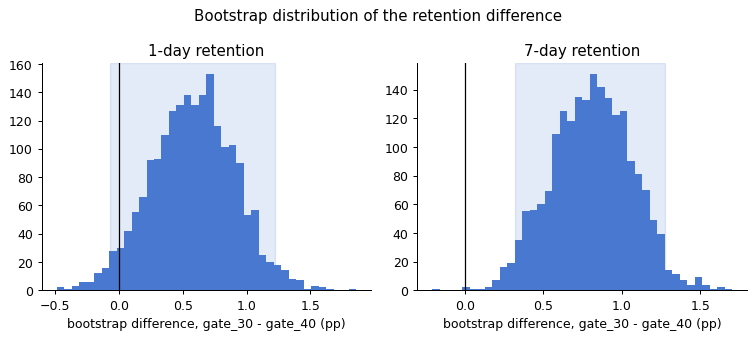

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8))
for ax, metric, title in zip(axes, ['retention_1', 'retention_7'],
                             ['1-day retention', '7-day retention']):
    d = boot[metric] * 100
    ax.hist(d, bins=40, color='#4878d0')
    lo, hi = np.percentile(d, [2.5, 97.5])
    ax.axvline(0, color='black', linewidth=1)
    ax.axvspan(lo, hi, alpha=0.15, color='#4878d0')
    ax.set_title(title)
    ax.set_xlabel('bootstrap difference, gate_30 - gate_40 (pp)')
fig.suptitle('Bootstrap distribution of the retention difference')
fig.tight_layout()
plt.show()

Same story as the z-test, with no normality assumption: the day-7 difference clears zero in 99.9% of resamples, while the day-1 difference straddles it (about 96% on one side). When two methods with different assumptions agree, I trust the direction.

## 8. Power and sample size

Two questions worth asking of any test. Was it big enough to catch a real effect, and what's the smallest effect it could have caught?

In [12]:
def power_two_proportions(p1, p2, n, alpha=0.05):
    """Approximate power of a two-sided two-proportion z-test, n per group."""
    za = stats.norm.ppf(1 - alpha / 2)
    p_bar = (p1 + p2) / 2
    se0 = np.sqrt(2 * p_bar * (1 - p_bar) / n)
    se1 = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
    return stats.norm.cdf((abs(p1 - p2) - za * se0) / se1)

def n_required(p1, p2, alpha=0.05, power=0.8):
    za = stats.norm.ppf(1 - alpha / 2)
    zb = stats.norm.ppf(power)
    p_bar = (p1 + p2) / 2
    num = (za * np.sqrt(2 * p_bar * (1 - p_bar))
           + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return num / (p1 - p2) ** 2

p30 = df.loc[df['version'] == 'gate_30', 'retention_7'].mean()
p40 = df.loc[df['version'] == 'gate_40', 'retention_7'].mean()
n_per_group = (df['version'] == 'gate_30').sum()

# smallest detectable effect at 80% power, found by bisection
lo, hi = 1e-4, 0.2
for _ in range(60):
    mid = (lo + hi) / 2
    if power_two_proportions(p30, p30 - mid, n_per_group) >= 0.8:
        hi = mid
    else:
        lo = mid

print(f'n per group:               {n_per_group:,}')
print(f'baseline 7-day retention:  {p30:.1%}')
print(f'smallest detectable drop:  {hi*100:.2f} pp (at 80% power)')
print(f'power for observed drop:   {power_two_proportions(p30, p40, n_per_group):.2f}')
print(f'n per group needed for the observed {abs(p30-p40)*100:.2f} pp drop: {n_required(p30, p40):,.0f}')

n per group:               44,700
baseline 7-day retention:  19.0%
smallest detectable drop:  0.73 pp (at 80% power)
power for observed drop:   0.88
n per group needed for the observed 0.82 pp drop: 35,349


At ~44.7k players per group and a 19% baseline, the test could catch a day-7 drop of about **0.73 points or larger** with 80% power. The observed drop is 0.82 points, so the test was properly sized for the effect it found (retrospective power ~88%), and the design-time math agrees: detecting that drop needed ~35k per group, and they ran ~45k.

The flip side: anything smaller than ~0.7 points, say a 0.3 point drop, would likely have slipped through. "No significant difference" on this data would only rule out medium-and-up effects, not tiny ones. Worth remembering before calling any future null result a clean bill of health.